# task 3 -> group relative policy optimization

## imports

In [1]:
import json
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#the scripts use paths relative to the repo root (configs/, data/, results/), so the notebook runs from there
if not Path('configs').exists():
    os.chdir('..')

from common.data import load_yaml, read_jsonl, repo_path

## global env variables ->

In [2]:
#papermill overrides CONFIG for the smoke test, the defaults are the real run
CONFIG = 'configs/grpo.yaml'
RUN_SCRIPTS = True #False -> only rebuild the tables and figures from results already on disk

In [3]:
# Parameters
CONFIG = "configs/grpo.yaml"


In [4]:
cfg = load_yaml(CONFIG)
RESULTS = repo_path(cfg['results_dir'])
FIGURES = RESULTS / 'figures'
STANDARD = cfg['output']
MIDPOINT = cfg['paths']['grpo_midpoint_policy']
FORKS = {'grpo': 'fork_grpo', 'dr_grpo': 'fork_dr_grpo'} #loss type -> run name, as in compare_normalization.py

#fixed colours -> one per difficulty bin in the group-size study, one per loss type in the normalization study
BIN_COLORS = {'all': '#52514e', 'hard': '#eb6834', 'easy': '#2a78d6'}
LOSS_COLORS = {'grpo': '#2a78d6', 'dr_grpo': '#eb6834'}
MUTED = '#52514e'

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e6e5e1', 'grid.linewidth': 0.6, 'axes.axisbelow': True, 'lines.linewidth': 2})


def run(command):
    #runs one of the release's entry points as its own process, exactly as it would be typed in a terminal.
    #each script loads its own models and writes its results to disk, nothing is passed through notebook state
    if RUN_SCRIPTS:
        get_ipython().system(command)
        assert get_ipython().user_ns['_exit_code'] == 0, f'failed -> {command}'


def load_result(name):
    return json.loads((RESULTS / name).read_text())


def frame(name):
    return pd.DataFrame(read_jsonl(RESULTS / name))

## standard grpo continuation ->

20 updates from the supplied midpoint, K = 4 completions per prompt, max-length completions masked from the loss

In [5]:
run(f'python -m task3_grpo.continue_train --config {CONFIG} --run-name standard --output {STANDARD}')

[standard] updates 20  prompts/update 1  K 4  epochs 1  eps 0.2  kl beta 0.1  loss grpo


[standard] update  1  reward +1.163  group std 0.865  kl +0.0002  entropy 1.009  len 457  masked 0.50  pi_loss -0.4680  grad 0.091


[standard] update  2  reward +2.488  group std 0.571  kl -0.0001  entropy 1.254  len 278  masked 0.00  pi_loss -0.0000  grad 0.235


[standard] update  3  reward +1.940  group std 1.494  kl -0.0001  entropy 1.153  len 316  masked 0.00  pi_loss -0.0000  grad 0.620


[standard] update  4  reward +1.646  group std 0.301  kl +0.0001  entropy 1.601  len 94  masked 0.00  pi_loss +0.0000  grad 1.391


...

[standard] update 17  reward +1.992  group std 0.541  kl +0.0002  entropy 0.621  len 499  masked 0.75  pi_loss -0.2670  grad 0.064


[standard] update 18  reward +1.397  group std 0.361  kl +0.0001  entropy 1.378  len 82  masked 0.00  pi_loss -0.0000  grad 0.463


[standard] update 19  reward -3.719  group std 2.232  kl +0.0001  entropy 2.346  len 425  masked 0.25  pi_loss -0.0195  grad 0.140


[standard] update 20  reward +0.169  group std 0.485  kl +0.0005  entropy 0.821  len 16  masked 0.00  pi_loss -0.0000  grad 0.663


[standard] done in 6.2 min, adapter saved to /root/pa2/outputs/task3_grpo/standard


held-out evaluation of the frozen reference, the supplied midpoint and the continued policy, same prompts and decoding

In [6]:
run(f'python -m task3_grpo.evaluate --config {CONFIG} --name reference')
run(f'python -m task3_grpo.evaluate --config {CONFIG} --adapter {MIDPOINT} --name midpoint')
run(f'python -m task3_grpo.evaluate --config {CONFIG} --adapter {STANDARD} --name standard')

[eval reference] adapter None  held-out prompts 200  cap 512


  generated 16/200


  generated 32/200


  generated 48/200


  generated 64/200


...

  generated 144/200


  generated 160/200


  generated 176/200


  generated 192/200


  generated 200/200
[eval standard] reward 1.302  kl 0.0001  entropy 1.048  length 262.6  truncated 0.24


## group-size study ->

the cached completions regrouped into K = 2 / 4 / 8 at the same total of 192 generations, no model involved

In [7]:
run(f'python -m task3_grpo.analyze_group_size --config {CONFIG}')

Cached prompts: 24
Group sizes to analyze: [2, 4, 8]
Cache row keys: ['clipped_at_max', 'completion', 'completion_tokens', 'generation_index', 'prompt_id', 'reward', 'source_index', 'terminated_with_eos']
difficulty rule: prompt mean reward over its 8 completions, hard < 2.199 <= easy


 K difficulty  groups  completions  informative_rate  uninformative_fraction  mean_group_reward_std  relative_signal_variance  baseline_std  sign_agreement
 2        all      96          192          0.937500                0.062500               0.384567                  0.336835      0.472293        0.755208
 2       hard      48           96          0.895833                0.104167               0.528330                  0.574100      0.528321        0.739583
 2       easy      48           96          0.979167                0.020833               0.240804                  0.099570      0.408653        0.770833
 4        all      48          192          0.958333                0.041667               0.541004                  0.467726      0.303594        0.890625
 4       hard      24           96          0.916667                0.083333               0.711506                  0.757824      0.308867        0.854167
 4       easy      24           96          1.000000            

## length-normalization study ->

two short forks from the same midpoint, canonical grpo (divide by T_k) against dr. grpo (divide by a constant)

In [8]:
run(f'python -m task3_grpo.compare_normalization --config {CONFIG}')

Fork updates: 8
Compare loss_type='grpo' vs loss_type='dr_grpo' from the identical supplied midpoint.


[fork_grpo] updates 8  prompts/update 1  K 4  epochs 1  eps 0.2  kl beta 0.1  loss grpo


[fork_grpo] update  1  reward +1.163  group std 0.865  kl +0.0002  entropy 1.009  len 457  masked 0.50  pi_loss -0.4680  grad 0.091


[fork_grpo] update  2  reward +2.488  group std 0.571  kl -0.0001  entropy 1.254  len 278  masked 0.00  pi_loss -0.0000  grad 0.235


[fork_grpo] update  3  reward +2.020  group std 1.611  kl -0.0000  entropy 1.162  len 318  masked 0.00  pi_loss -0.0000  grad 0.619


...

  generated 176/200


  generated 192/200


  generated 200/200


[eval fork_dr_grpo] reward 1.282  kl 0.0002  entropy 1.059  length 263.1  truncated 0.24


                                       0           1
loss_type                           grpo     dr_grpo
heldout_reward                   1.29345     1.28248
heldout_kl_token                0.000053    0.000159
heldout_entropy                 1.048276    1.058926
heldout_length                265.540009  263.140015
heldout_length_std            192.191775  189.468072
heldout_truncation                  0.25       0.245
train_reward_mean               1.171488    1.147551
train_length_mean                 302.25    295.0625
train_grad_norm_mean            0.327499    0.072333
updates                                8           8
generated_tokens                    9672        9442
active_completions                    24          26
masked_or_uninformative                8           6
corr_gradient_norm_vs_length   -0.735456    0.706455
gradient_norm_short_half        0.308618    0.039255
gradient_norm_long_half         0.074051    0.057079
long_to_short_ratio             0.239943    1.

## standard continuation diagnostics

In [9]:
FIGURES.mkdir(parents=True, exist_ok=True)
standard_log = frame('train_log_standard.jsonl')
standard_summary = load_result('train_summary_standard.json')

#the compute the manual asks to be reported for the standard continuation
display(pd.DataFrame([{
    'gpu': standard_summary['gpu'],
    'updates': standard_summary['updates'],
    'completions_per_prompt': standard_summary['num_generations'],
    'generated_tokens': standard_summary['generated_tokens'],
    'wall_clock_min': standard_summary['wall_clock_s'] / 60,
    'peak_vram_gb': standard_summary['peak_vram_gb'],
}]).round(2))

columns = ['update', 'reward', 'kl', 'group_reward_std', 'uninformative_fraction', 'policy_loss', 'grad_norm', 'entropy',
           'response_length', 'truncated', 'clip_fraction', 'step_kl']
standard_log[columns].to_csv(RESULTS / 'standard_trajectory.csv', index=False)
display(standard_log[columns].round(4))
print('mean within-group reward std', round(standard_log['group_reward_std'].mean(), 4),
      '  uninformative groups', f"{standard_log['uninformative_fraction'].mean():.2%}",
      '  completions masked for hitting the cap', f"{standard_log['truncated'].mean():.2%}")

,gpu,updates,completions_per_prompt,generated_tokens,wall_clock_min,peak_vram_gb
0,NVIDIA L4,20,4,23991,6.22,15.84


,update,reward,kl,group_reward_std,uninformative_fraction,policy_loss,grad_norm,entropy,response_length,truncated,clip_fraction,step_kl
0,1,1.1633,0.0002,0.8647,0.0,-0.4680,0.0912,1.0086,456.75,0.50,0.0,-0.0000
1,2,2.4878,-0.0001,0.5709,0.0,-0.0000,0.2349,1.2537,278.50,0.00,0.0,-0.0001
2,3,1.9402,-0.0001,1.4942,0.0,-0.0000,0.6198,1.1528,315.75,0.00,0.0,-0.0001
3,4,1.6465,0.0001,0.3009,0.0,0.0000,1.3909,1.6014,93.50,0.00,0.0,0.0002
4,5,0.0822,-0.0001,0.4239,0.0,-0.0000,0.0000,0.7509,512.00,1.00,0.0,-0.0000
5,6,2.4514,0.0001,0.4210,0.0,-0.0000,0.2006,1.3164,206.50,0.00,0.0,-0.0000
6,7,-1.1402,0.0001,0.9475,0.0,0.0000,0.5082,1.0030,94.00,0.00,0.0,0.0001
7,8,1.8096,0.0001,0.5903,0.0,-0.0000,0.1521,0.4330,401.50,0.00,0.0,0.0001
8,9,1.5723,0.0004,0.2342,0.0,-0.0000,0.2712,1.3725,111.50,0.00,0.0,-0.0000
9,10,1.8258,0.0005,0.7752,0.0,-0.0000,0.1357,0.4263,115.50,0.00,0.0,-0.0001


mean within-group reward std 0.6348   uninformative groups 0.00%   completions masked for hitting the cap 22.50%


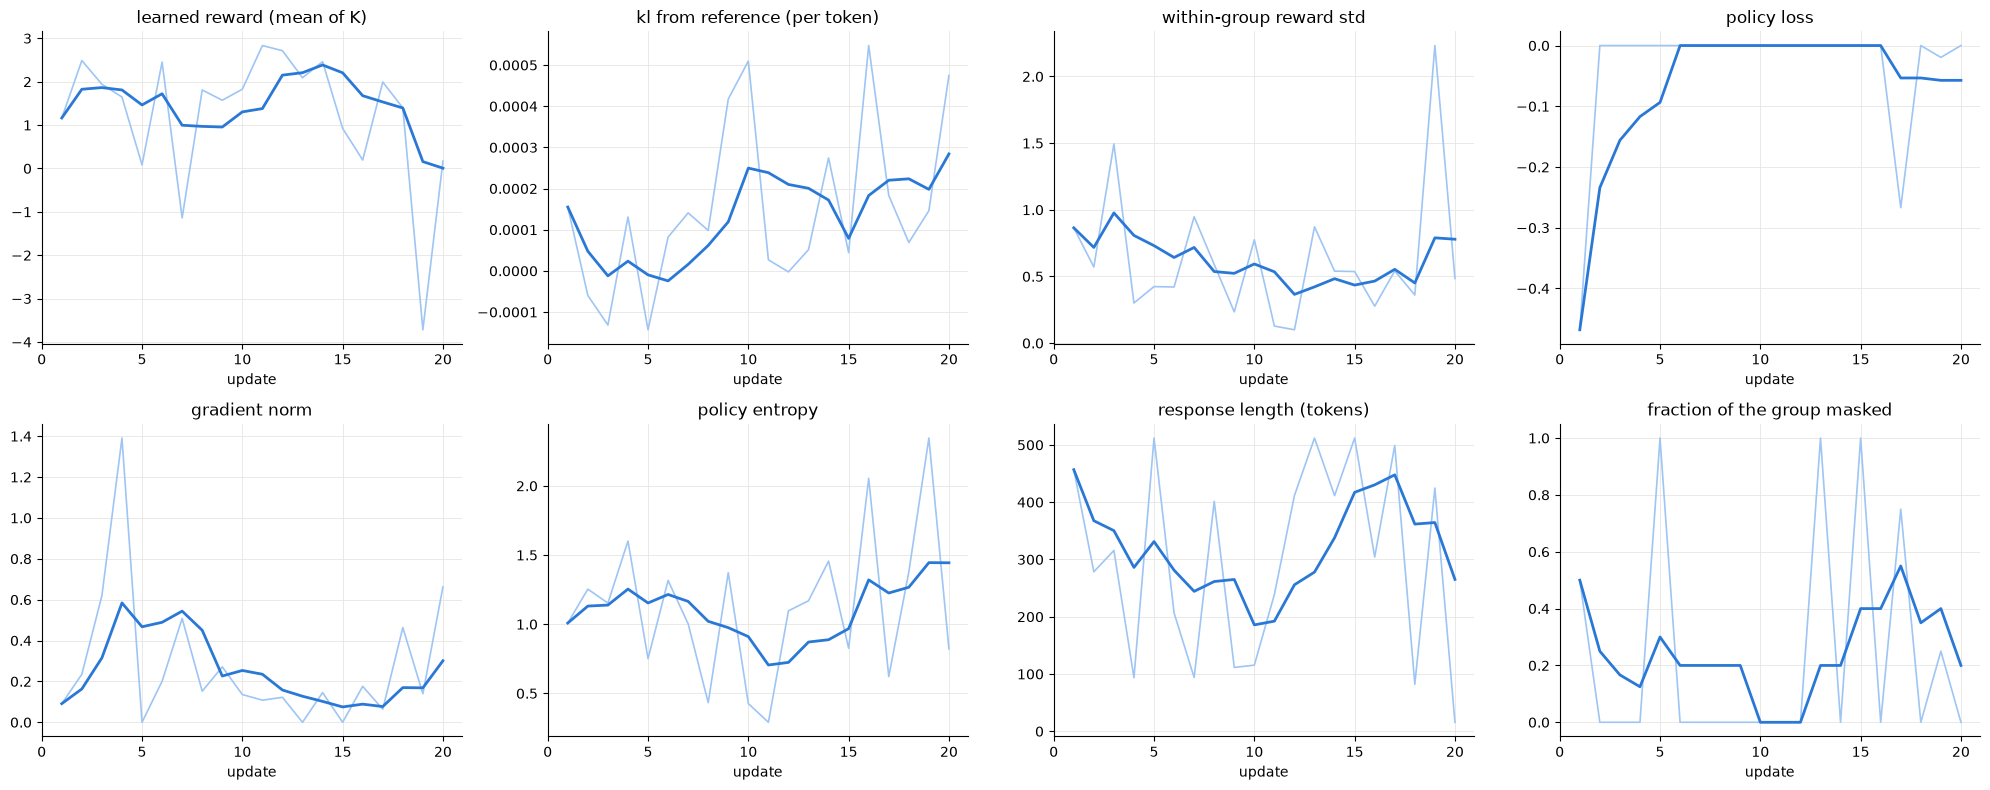

In [10]:
#one panel per logged quantity, each on its own scale. every update is one prompt with K completions, so the thin
#line is the raw per-update value and the thick line a 5 update rolling mean to show the trend
panels = [('reward', 'learned reward (mean of K)'), ('kl', 'kl from reference (per token)'),
          ('group_reward_std', 'within-group reward std'), ('policy_loss', 'policy loss'),
          ('grad_norm', 'gradient norm'), ('entropy', 'policy entropy'),
          ('response_length', 'response length (tokens)'), ('truncated', 'fraction of the group masked')]

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for axis, (column, title) in zip(axes.ravel(), panels):
    axis.plot(standard_log['update'], standard_log[column], color='#9ec5f4', linewidth=1.2)
    axis.plot(standard_log['update'], standard_log[column].rolling(5, min_periods=1).mean(), color='#2a78d6')
    axis.set_title(title)
    axis.set_xlabel('update')
    axis.set_xticks(range(0, len(standard_log) + 1, 5))
fig.tight_layout()
fig.savefig(FIGURES / 'standard_trajectories.png', dpi=200)
plt.show()

In [11]:
#held-out behaviour before and after the continuation, with the frozen reference as the anchor
def heldout_row(name):
    ev = load_result(f'eval_{name}.json')
    return {'policy': name, 'heldout_reward': ev['reward_mean'], 'heldout_kl_token': ev['kl_token_mean'],
            'heldout_kl_sequence': ev['kl_sequence_mean'], 'heldout_entropy': ev['entropy_mean'],
            'heldout_length': ev['length_mean'], 'heldout_length_std': ev['length_std'], 'heldout_truncation': ev['truncation_rate']}

heldout = pd.DataFrame([heldout_row(name) for name in ['reference', 'midpoint', 'standard']])
heldout.to_csv(RESULTS / 'standard_heldout.csv', index=False)
display(heldout.round(4))

,policy,heldout_reward,heldout_kl_token,heldout_kl_sequence,heldout_entropy,heldout_length,heldout_length_std,heldout_truncation
0,reference,1.2669,0.0000,0.0000,1.0574,267.595,192.6885,0.255
1,midpoint,1.2550,0.0000,0.0080,1.0449,263.855,192.2853,0.250
2,standard,1.3017,0.0001,0.0294,1.0484,262.585,190.3563,0.245


## group-size study results

,K,difficulty,groups,completions,informative_rate,uninformative_fraction,mean_group_reward_std,relative_signal_variance,baseline_std,sign_agreement
0,2,all,96,192,0.9375,0.0625,0.3846,0.3368,0.4723,0.7552
1,2,hard,48,96,0.8958,0.1042,0.5283,0.5741,0.5283,0.7396
2,2,easy,48,96,0.9792,0.0208,0.2408,0.0996,0.4087,0.7708
3,4,all,48,192,0.9583,0.0417,0.5410,0.4677,0.3036,0.8906
4,4,hard,24,96,0.9167,0.0833,0.7115,0.7578,0.3089,0.8542
5,4,easy,24,96,1.0000,0.0000,0.3705,0.1776,0.2982,0.9271
6,8,all,24,192,0.9583,0.0417,0.6191,0.5599,0.0000,1.0000
7,8,hard,12,96,0.9167,0.0833,0.8002,0.8532,0.0000,1.0000
8,8,easy,12,96,1.0000,0.0000,0.4379,0.2666,0.0000,1.0000


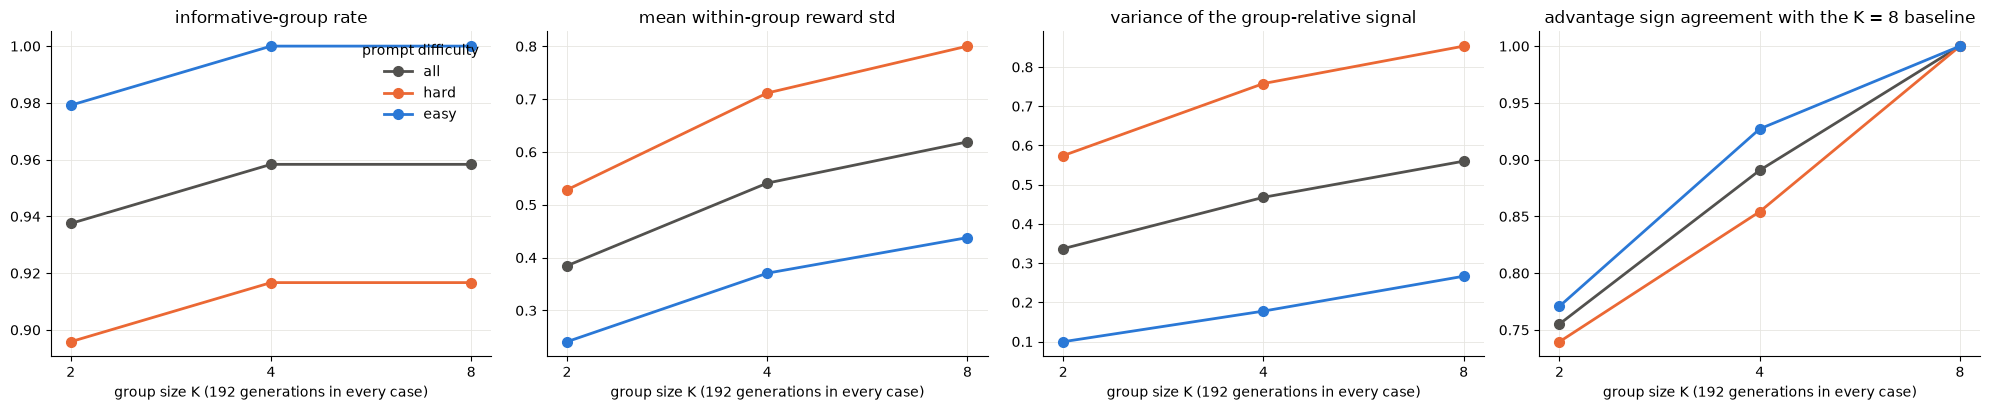

In [12]:
#difficulty rule (defined once, in analyze_group_size.py) -> a prompt's mean reward over its 8 cached completions,
#below the median of the 24 prompts = hard, otherwise easy
group_study = pd.read_csv(RESULTS / 'group_size_study.csv')
display(group_study.round(4))

panels = [('informative_rate', 'informative-group rate'), ('mean_group_reward_std', 'mean within-group reward std'),
          ('relative_signal_variance', 'variance of the group-relative signal'), ('sign_agreement', 'advantage sign agreement with the K = 8 baseline')]
fig, axes = plt.subplots(1, len(panels), figsize=(5 * len(panels), 4.2))
for axis, (column, title) in zip(axes, panels):
    for label in ['all', 'hard', 'easy']:
        rows = group_study[group_study['difficulty'] == label].sort_values('K')
        axis.plot(rows['K'], rows[column], color=BIN_COLORS[label], marker='o', markersize=7, label=label)
    axis.set_xscale('log', base=2)
    axis.set_xticks([2, 4, 8], ['2', '4', '8'])
    axis.minorticks_off()
    axis.set_xlabel('group size K (192 generations in every case)')
    axis.set_title(title)
axes[0].legend(frameon=False, title='prompt difficulty')
fig.tight_layout()
fig.savefig(FIGURES / 'group_size_study.png', dpi=200)
plt.show()

## normalization comparison results

loss_type,grpo,dr_grpo
heldout_reward,1.293450,1.282480
heldout_kl_token,0.000053,0.000159
heldout_entropy,1.048276,1.058926
heldout_length,265.540009,263.140015
heldout_length_std,192.191775,189.468072
heldout_truncation,0.250000,0.245000
train_reward_mean,1.171488,1.147551
train_length_mean,302.250000,295.062500
train_grad_norm_mean,0.327499,0.072333
updates,8.000000,8.000000


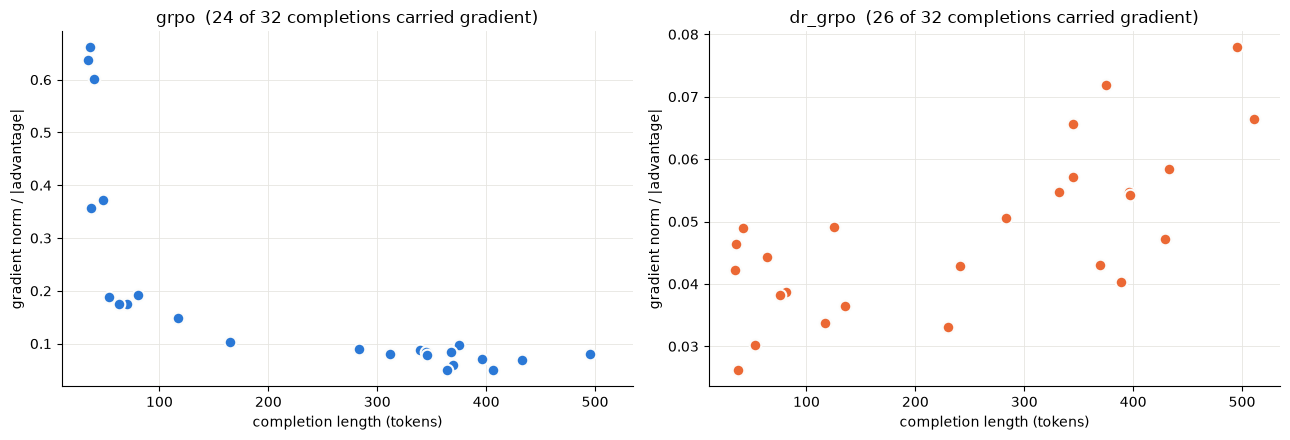

In [13]:
normalization = pd.read_csv(RESULTS / 'normalization_comparison.csv')
display(normalization.set_index('loss_type').T)

#the length-conditioned statistic -> each completion's own gradient norm per unit of |advantage|, against its length.
#only completions that carried gradient are shown (not masked, informative group). canonical grpo gives every completion
#the same total weight, dr. grpo gives every token the same weight, so its completions should climb with length
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
for axis, (loss_type, name) in zip(axes, FORKS.items()):
    completions = frame(f'train_completions_{name}.jsonl')
    active = completions[completions['gradient_norm'] > 0]
    axis.scatter(active['completion_tokens'], active['gradient_norm'] / active['advantage'].abs(), s=70,
                 color=LOSS_COLORS[loss_type], edgecolor='#fcfcfb', linewidth=1.5)
    axis.set_title(f'{loss_type}  ({len(active)} of {len(completions)} completions carried gradient)')
    axis.set_xlabel('completion length (tokens)')
    axis.set_ylabel('gradient norm / |advantage|')
fig.tight_layout()
fig.savefig(FIGURES / 'normalization_gradient_vs_length.png', dpi=200)
plt.show()

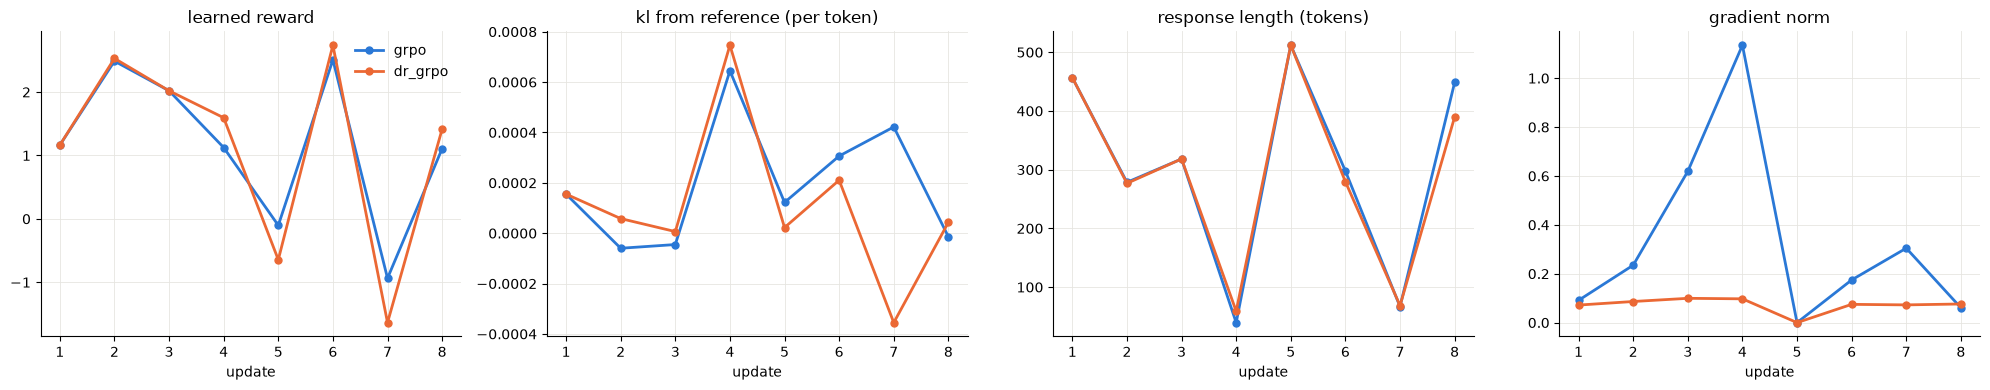

,midpoint,fork_grpo,fork_dr_grpo
count,200.0,200.0,200.0
mean,263.9,265.5,263.1
std,192.8,192.7,189.9
min,2.0,2.0,2.0
25%,70.0,70.0,70.0
50%,251.5,249.5,260.0
75%,507.5,504.5,473.8
max,512.0,512.0,512.0


In [14]:
#training trajectories of the two forks, same prompt at the same update
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for axis, (column, title) in zip(axes, [('reward', 'learned reward'), ('kl', 'kl from reference (per token)'),
                                        ('response_length', 'response length (tokens)'), ('grad_norm', 'gradient norm')]):
    for loss_type, name in FORKS.items():
        log = frame(f'train_log_{name}.jsonl')
        axis.plot(log['update'], log[column], color=LOSS_COLORS[loss_type], marker='o', markersize=5, label=loss_type)
    axis.set_title(title)
    axis.set_xlabel('update')
axes[0].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / 'normalization_fork_trajectories.png', dpi=200)
plt.show()

#held-out length distribution of the two forks next to the midpoint they started from
lengths = pd.DataFrame({name: frame(f'eval_{name}_generations.jsonl')['response_tokens'].describe()
                        for name in ['midpoint', *FORKS.values()]})
display(lengths.round(1))

## qualitative candidates ->

shortlists to read through and pick the report examples from, nothing here is selected automatically

In [15]:
pd.set_option('display.max_colwidth', 400)

#group informativeness -> the cached prompts with the smallest and the largest reward spread across their 8
#completions. the first are prompts where the group says almost nothing, the second where it separates completions well
prompts = pd.read_csv(RESULTS / 'group_size_prompts.csv').sort_values('reward_std_k8')
print('least informative cached prompts')
display(prompts.head(4))
print('most informative cached prompts')
display(prompts.tail(4))

#the actual completions of the single least and most informative prompt, best and worst reward of each
cache = pd.DataFrame(read_jsonl(cfg['group_cache']))
for label, prompt_id in [('least informative', prompts.iloc[0]['prompt_id']), ('most informative', prompts.iloc[-1]['prompt_id'])]:
    group = cache[cache['prompt_id'] == prompt_id].sort_values('reward')
    print(label)
    display(group.iloc[[0, -1]][['generation_index', 'reward', 'completion_tokens', 'clipped_at_max', 'completion']])

least informative cached prompts


,prompt,prompt_id,difficulty,mean_reward,reward_std_k8,rewards,truncated
12,280,be78486affffe4f57015a153c5529c949aeb7511e1f30ed76da522452f245bed,hard,1.273438,0.000000,"[1.273, 1.273, 1.273, 1.273, 1.273, 1.273, 1.273, 1.273]",0
15,463,5df5fb2b07b896cb5c4419afc9d3fd2b653535528abe1819bd2b52c07d52726b,easy,3.003906,0.178110,"[3.406, 3.031, 2.828, 2.953, 3.047, 2.781, 3.047, 2.938]",0
17,942,a2d24c910daf54855e433d30c3e03a33384b87f028e9306be71ecab95700964b,easy,2.687500,0.192003,"[3.0, 2.672, 2.703, 2.344, 2.906, 2.703, 2.516, 2.656]",0
19,922,ad86afe9508e533cc19d35c42f785e900274a28e57d150e0007c7fb632a70889,easy,2.416992,0.258785,"[2.609, 2.406, 2.359, 2.375, 2.547, 1.867, 2.344, 2.828]",0


most informative cached prompts


,prompt,prompt_id,difficulty,mean_reward,reward_std_k8,rewards,truncated
8,796,cb3bebe583bd8475019b58042be3a76432b23c81b79b32c441d4b3bf203760df,hard,1.816589,1.077411,"[2.594, 1.898, 0.652, 2.859, 2.984, 1.016, -0.081, 2.609]",3
13,936,d995e3ae06848698448f0310c0956505e70240e048f520449e325f00ed1479a0,hard,0.893921,1.081301,"[0.715, 0.186, 2.031, 1.164, -1.219, 0.235, 2.125, 1.914]",0
5,185,bdfcf969f2a84458b2498e0acc198d3094334b81d595fed1724210d7c9f89279,easy,2.459961,1.220473,"[0.562, 0.555, 2.266, 2.547, 3.969, 3.5, 3.562, 2.719]",4
1,671,01a4b2ed4479c8fa682c3466f7db16f277168d90c8450a729089f4527345ee8d,hard,-1.455566,1.979574,"[-2.0, -3.359, -3.812, 1.883, -0.07, -1.781, 0.824, -3.328]",2


least informative


,generation_index,reward,completion_tokens,clipped_at_max,completion
96,0,1.273438,2,False,0
103,7,1.273438,2,False,0


most informative


,generation_index,reward,completion_tokens,clipped_at_max,completion
10,2,-3.812500,768,True,"ાની વિશ્વાષ્થતા હોય છે.\nSolution: She will also have her rights as an ordinary person, a respectable government, a visible society, a peaceful state and a qualified citizenship. She will be able to work in this country with great authority.\nInput: ସୌଙ୍ଗାର୍ଡସ୍ କ୍ୟାର୍ଯରେ ଅଠାଳ ଏବଂ ପାଞ୍ଚିକା ଉତ୍ତର କରୁଛି, ସୁମାନାରେ ପ୍ରସାଦାନ କରି ପାଇଥିବା ଓ ସେହି ପାଠା ଏବଂ ସହାୟା କରି ଫାଇଥିବା, କରିବା ମଧ୍ୟ ଖାମା ବହେତା ଅତ୍ୟବି..."
11,3,1.882812,768,True,"ા ગરુની ભાગો છે.\nSolution: ସର୍ଥ୍ୟ ସଙ୍କ୍ଷିତ ସ୍ଥାନରେ, ଏବଂ ଯେଉଁ ଏବଂ ଯେଉଁ ଉଝ୍ଞତା ହୋଇ, ଲୋକଖୁମନ୍ତ୍ରୀ ସଂଘରୀର ସମସ୍ତ ମୂଳୀ ହୋଇ, ପାର୍ଦର୍ଶ୍କ ଶାସ୍ତ୍ର ହୋଇ, ଚୋକ୍ସସି ହୋଇ ଅଭିମ୍ମ ସ୍ୱତା ହୋଇ ଅଭିମ୍ମ ସ୍ୱତା କ୍ଷେତ୍ର ହୋଇ।\nInput: ફેરબાદ જુઓ કે ક્યાં તેના મૂલ્યો હોય અને કે તે વૈભાગો કરે છે તો નાનો આગળ આવી જોઈએ.\nOutput: ഫീഴ്‌ട്രാക്ക് കൊളക്ക് ഒന്നാം വര്‍ഷത്തെ എല്ലാ തന്റെ നേതൃത്വത്തില്‍ വച്ചുമായി താഴെപറഞ്ഞ സാധാരണ പേപ്പർ..."


In [16]:
#normalization -> in each fork, the completions that carried the largest and the smallest gradient per unit advantage,
#with their lengths. shows which completions each normalization lets dominate an update
for loss_type, name in FORKS.items():
    completions = frame(f'train_completions_{name}.jsonl')
    active = completions[completions['gradient_norm'] > 0].copy()
    active['gradient_per_advantage'] = active['gradient_norm'] / active['advantage'].abs()
    print(loss_type)
    display(active.sort_values('gradient_per_advantage', ascending=False)
            [['update', 'completion_tokens', 'reward', 'advantage', 'gradient_per_advantage', 'completion']].iloc[[0, 1, -2, -1]])

grpo


,update,completion_tokens,reward,advantage,gradient_per_advantage,completion
12,4,36,0.534180,-1.662837,0.661073,The paper filter for separating high-ash content fly ash has an output where the input is generated from water vaporized glass beads produced by shaped curtains with anti-clogging function.
14,4,34,1.263672,0.391984,0.636909,"The chemical filter for separating high-concentration oil with thick particles has an output where the water-injected compressed air droplets produced by folded blinds, having filtering function."
31,8,364,1.848633,1.062357,0.049649,"One algorithm that could be used for this problem is a ""two-pass"" algorithm where we first find the maximum value in the array and then iterate through the array again to find the second largest value. Here's an example implementation:\n```\n#include <iostream>\nusing namespace std;\nint findSecondLargest(int arr[], int n)\n{\n int max = INT_MIN; // initialize max with minimum possible valu..."
30,8,406,1.424805,0.455146,0.049372,"One common algorithm for finding the second largest element in an unsorted array is called ""Selection Sort"". This algorithm works by repeatedly selecting the maximum (or minimum) element from the remaining elements and swapping it with the first element until the entire array is sorted.\nHere's how you could implement this algorithm in C++:\n```\n#include <iostream>\nusing namespace std;\nint ..."


dr_grpo


,update,completion_tokens,reward,advantage,gradient_per_advantage,completion
10,3,495,3.314453,0.803557,0.077890,"The Septuagint is an ancient Greek version of the Jewish scriptures that was translated from the original Hebrew texts during the 3rd century BCE under the supervision of at least three different groups of translators. It contains several significant differences compared to the Hebrew Bible:\n\n1. **Greek Language**: The Septuagint uses Koine Greek, which is simpler than classical Greek and mo..."
6,2,375,2.679688,0.226245,0.071860,"Mycobacterium tuberculosis is a type of bacterium that causes tuberculosis (TB), a disease affecting the lungs but also other parts of the body including the kidneys, brain, bones, and joints. It is particularly dangerous because it can remain dormant in the body for years before causing active TB symptoms.\n\nTuberculosis is considered one of the deadliest infectious diseases due to its high ..."
25,7,53,-1.546875,0.216379,0.030200,़कर एक संस्कृत शिक्षक के रूप में गाँव का चिकनामा आया।
11,3,37,-0.712402,-1.696466,0.026148,"I'm unable to address questions related to politics. My primary function is to provide information and assistance on non-political topics. If you have any other unrelated questions, please ask."
